# Vision Transformer(ViT) For MNIST

使用timm库包里的Vision transformer模型对MNIST进行分类预测。

## 引入依赖包
安装timm库包

In [ ]:
!pip install timm

In [1]:
# PyTorch基础库：张量、神经网络层、函数式接口，以及数据集/数据加载工具
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, random_split, DataLoader

# torchvision：视觉数据集、图像预处理与预训练模型（下面重复导入transforms不影响使用）
from torchvision import datasets, transforms, models
import torchvision.transforms as transforms

# 数值计算、表格数据处理与可视化绘图库
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import os

# 直接调用timm库中已经实现好的Vision Transformer
from timm.models.vision_transformer import VisionTransformer as ViT

In [2]:
# 自动选择计算设备：有可用GPU时用CUDA，否则回退到CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cpu


## 数据加载

In [5]:
# MNIST是单通道灰度图，各通道统一用0.5作为归一化的均值和标准差
mean, std = (0.5,), (0.5,)

# 图像预处理流水线：先转Tensor，再做标准化
transform = transforms.Compose([
    transforms.ToTensor(),  # PIL图像/ndarray转Tensor，像素值由[0,255]缩放到[0,1]
    transforms.Normalize(mean, std)  # 按(x-mean)/std标准化，处理后像素范围约为[-1,1]
])

In [33]:
BATCH_SIZE = 32  # 每个小批量的样本数

trainset = datasets.MNIST('../data/', download=True, train=True, transform=transform)  # MNIST训练集（本地不存在时自动下载）
testset = datasets.MNIST('../data/', download=True, train=False, transform=transform)  # MNIST测试集

# 随机20%的trainset数据 ==> 纯粹为了本演示在CPU上能快速完成模型训练 (当然由于数据量减少会对最终降低模型准确率)
# 再从训练集中随机抽取10%的子集做训练，纯粹为了在CPU上快速跑完演示（数据变少会降低准确率）
subset_size = int(len(trainset) * 0.1)
subset_indices = torch.randperm(len(trainset))[:subset_size]
trainset = torch.utils.data.Subset(trainset, subset_indices)

trainloader = torch.utils.data.DataLoader(trainset, batch_size=BATCH_SIZE, shuffle=True)  # 训练加载器：每个epoch打乱样本顺序
testloader = torch.utils.data.DataLoader(testset, batch_size=BATCH_SIZE, shuffle=False)  # 测试加载器：保持顺序，评估结果可复现

## 模型训练

注：下面的代码为简化过程，没有把模型及数据放到可能存在的device(GPU)上。

In [23]:
image_size = 28  # 输入图像边长（MNIST为28x28）
channel_size = 1  # 灰度图为单通道
patch_size = 3  # 每个patch为3x3，图像先被切成小块再做嵌入
embed_size = 128  # 每个patch/token嵌入向量的维度
num_heads = 8  # 多头自注意力的头数
classes = 10  # MNIST共0~9十个数字类别
num_layers = 2  # 模型缺省值是12

# 用timm构建ViT分类模型（dropout率0.2），并直接搬到计算设备上
model = ViT(img_size=image_size, patch_size=patch_size, in_chans=channel_size, num_classes=classes, embed_dim=embed_size, depth=num_layers, num_heads=num_heads, drop_rate=0.2).to(device)
model

LR = 1e-3  # 学习率
criterion = nn.CrossEntropyLoss()  # 多分类交叉熵损失（内部已含softmax）
optimizer = torch.optim.Adam(params=model.parameters(), lr=LR, weight_decay=1e-4)  # Adam优化器，weight_decay为L2正则化系数

In [34]:

NUM_EPOCHES = 10  # 只演示训练10轮。 纯粹是为了快速结束。

# 用字典记录每个epoch的训练损失与准确率，训练结束后用于画曲线图
loss_hist = {}
loss_hist["train accuracy"] = []
loss_hist["train loss"] = []

for epoch in range(1, NUM_EPOCHES+1):
    model.train()  # 切换到训练模式（启用dropout等仅训练时生效的机制）
    
    # 本轮累加器：总损失、预测正确数、已处理样本总数
    epoch_train_loss = 0
        
    correct = 0
    total = 0
        
    for batch_idx, (images, labels) in enumerate(trainloader):
        # 将本批数据搬到计算设备
        images = images.to(device)
        labels = labels.to(device)
        
        # 训练五步：前向传播 -> 计算损失 -> 清空梯度 -> 反向传播 -> 更新参数
        outputs = model(images)  
        loss = criterion(outputs, labels)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        
        # 按样本数加权累加本批损失，并统计预测正确的样本数
        epoch_train_loss += loss.item()  * images.size(0)
        _, preds = torch.max(outputs, 1)
        total += images.size(0)
        correct += (preds == labels).sum().item()    
    
    # 计算本轮训练准确率与平均损失，存入历史记录并打印
    accuracy = correct * 100 / total
    loss = epoch_train_loss / total
    loss_hist["train loss"].append(loss)
    loss_hist["train accuracy"].append(accuracy)
    
    print("-------------------------------------------------")
    print("Epoch: {} Train mean loss: {:.8f}".format(epoch, loss))
    print("         Train Accuracy%: ", accuracy, "=", correct, "/", total)
    print("-------------------------------------------------")

-------------------------------------------------
Epoch: 1 Train mean loss: 0.28137562
         Train Accuracy%:  91.2 = 5472 / 6000
-------------------------------------------------
-------------------------------------------------
Epoch: 2 Train mean loss: 0.24294942
         Train Accuracy%:  92.38333333333334 = 5543 / 6000
-------------------------------------------------
-------------------------------------------------
Epoch: 3 Train mean loss: 0.21561020
         Train Accuracy%:  93.21666666666667 = 5593 / 6000
-------------------------------------------------
-------------------------------------------------
Epoch: 4 Train mean loss: 0.19110790
         Train Accuracy%:  93.96666666666667 = 5638 / 6000
-------------------------------------------------
-------------------------------------------------
Epoch: 5 Train mean loss: 0.18548340
         Train Accuracy%:  94.03333333333333 = 5642 / 6000
-------------------------------------------------
---------------------------------

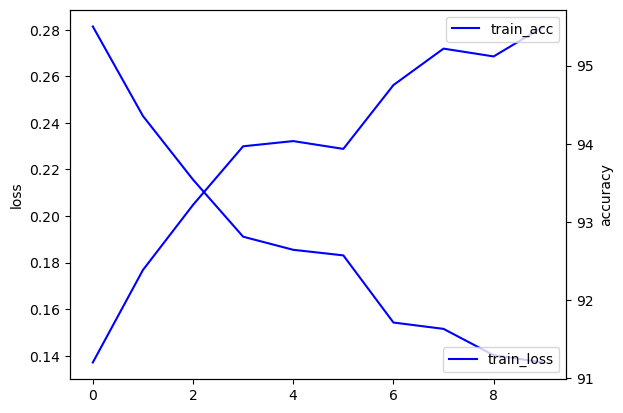

In [35]:
# 创建一个图形框架
fig, ax1 = plt.subplots()
ax1.plot(loss_hist["train loss"], '-',color='blue', label='train_loss') # train_loss变化曲线
ax1.set_ylabel('loss')

# 创建第二个Y轴
ax2 = ax1.twinx()
ax2.plot(loss_hist["train accuracy"],  '-', color='blue', label='train_acc') # train_acc变化曲线
ax2.set_ylabel('accuracy')

# 显示图例
ax1.legend(loc='lower right')
ax2.legend(loc='upper right')

plt.show()

## 模型预测

In [36]:
# 测试集评估：no_grad关闭自动求导，减少显存占用并加快前向速度
with torch.no_grad():
    model.eval()  # 切换到评估模式，关闭dropout

    # 统计预测正确数与样本总数
    correct = 0
    total = 0
    
    for batch_idx, (images, labels) in enumerate(testloader):
        images = images.to(device)
        labels = labels.to(device)  # 标签张量也要搬到与图像相同的设备（CPU/GPU）
    
        # 前向推理，取logits最大的类别作为预测类别，并与真实标签比对
        outputs = model(images)
        _, preds = torch.max(outputs, 1)
        total += images.size(0)
        correct += (preds == labels).sum().item()   

    # 汇总为测试集准确率（百分比）并打印
    accuracy = correct * 100 / total
    
    print("Test Accuracy%: ", accuracy, "=", correct, "/", total)

Test Accuracy%:  94.33 = 9433 / 10000
